In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Install required libraries (run this first)
!pip install pandas openpyxl rouge-score bert-score sentence-transformers scikit-learn nltk -q

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 2.9 MB/s eta 0:00:00


In [ ]:
# Import libraries
import pandas as pd
import numpy as np
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from rouge_score import rouge_scorer
from bert_score import score as bert_score
from sentence_transformers import CrossEncoder
import warnings
warnings.filterwarnings('ignore')
import nltk
nltk.download('punkt', quiet=True)
nltk.download('stopwords', quiet=True)

True

# PART 1: LOAD DATA FROM EXCEL

In [ ]:

# Upload your Excel file
from google.colab import files
print("Please upload your Excel file:")
uploaded = files.upload()
excel_file = list(uploaded.keys())

# Read the Excel file
df = pd.read_excel(excel_file[0])

print(f"Data loaded successfully!")
print(f"Shape: {df.shape}")
print(f"\nColumns: {df.columns.tolist()}")
print(f"\nFirst few rows:")
print(df.head())

Please upload your Excel file:


Saving Copy of Last_corrected (1) (1).xlsx to Copy of Last_corrected (1) (1).xlsx
Data loaded successfully!
Shape: (26, 14)

Columns: ['Type', 'Question', 'Answer', 'Answer1', 'InternVL-3.5', 'InternVL-3.5 latency', 'Gemma 3', 'Gemma 3 latency', 'Qwen2', 'Qwen2 latency', 'Phi3', 'Phi3 Latency', 'Vilt + Roberta', 'Vilt + Roberta Latency']

First few rows:
      Type                                           Question  \
0  Factoid  What are the animal found dead in Kaziranga Na...   
1  Factoid  In which place of Cachar district, landslide o...   
2  Factoid  What is the epicenter of earthquake in july 16...   
3  Factoid  Which are the states remained snapped during t...   
4  Factoid  What was the magnitude of earthquake in the ep...   

                                              Answer  \
0  The carcass of 13 rhinos, 10 swamp deer, 28 wi...   
1  A landslide occurred at the Bandarkhal portion...   
2  The epicenter is said to be 25 km away from As...   
3  The neighbouring states o

#Clean your data before evaluation—convert NaN to empty strings:

In [ ]:
def clean_predictions(df, model_columns):
    """Convert NaN to empty strings BEFORE evaluation"""
    df_clean = df.copy()

    for col in model_columns:
        # Step 1: Convert to string (handles NaN → 'nan' string)
        df_clean[col] = df_clean[col].astype(str)

        # Step 2: Replace string 'nan' with empty string
        df_clean[col] = df_clean[col].str.replace('nan', '', regex=False)

        # Step 3: Normalize whitespace
        df_clean[col] = df_clean[col].str.strip()

    return df_clean

# Model columns
model_columns = ['InternVL-3.5', 'Gemma 3', 'Qwen2', 'Phi3', 'Vilt + Roberta']

# Apply BEFORE computing metrics
df = clean_predictions(df,model_columns)

In [ ]:
def compute_bertscore_safe(predictions, ground_truths, batch_size=16):
    """BERTScore with comprehensive error handling"""
    try:
        # Ensure strings
        predictions = [str(p).strip() for p in predictions]
        ground_truths = [str(g).strip() for g in ground_truths]

        P, R, F1 = bert_score(predictions, ground_truths, ...)
        return F1.numpy()
    except Exception as e:
        print(f"BERTScore error: {e}")
        return np.array([0.0] * len(predictions))


# PART 2: DEFINE EVALUATION FUNCTIONS


In [ ]:
# 1. EXACT MATCH (EM)
def compute_em(prediction, ground_truth):
    """
    Exact Match: Binary metric (1 if prediction matches ground truth, 0 otherwise)
    """
    def normalize(text):
        """Normalize text for comparison"""
        return ' '.join(word_tokenize(str(text).lower()))

    return 1.0 if normalize(prediction) == normalize(ground_truth) else 0.0

In [ ]:
# 2. F1 SCORE
def compute_f1(prediction, ground_truth):
    """
    F1 Score: Token-level overlap metric
    F1 = 2 * (Precision * Recall) / (Precision + Recall)
    """
    def normalize(text):
        return set(word_tokenize(str(text).lower()))

    pred_tokens = normalize(prediction)
    truth_tokens = normalize(ground_truth)

    common = pred_tokens & truth_tokens

    if len(common) == 0:
        return 0.0

    precision = len(common) / len(pred_tokens) if len(pred_tokens) > 0 else 0
    recall = len(common) / len(truth_tokens) if len(truth_tokens) > 0 else 0

    if precision + recall == 0:
        return 0.0

    f1 = 2 * (precision * recall) / (precision + recall)
    return f1

In [ ]:
# 3. BLEU SCORE
def compute_bleu(prediction, ground_truth, max_n=4):
    """
    BLEU Score: N-gram precision with brevity penalty
    """
    from collections import Counter

    def get_ngrams(tokens, n):
        """Get n-grams from tokens"""
        ngrams = []
        for i in range(len(tokens) - n + 1):
            ngrams.append(' '.join(tokens[i:i+n]))
        return ngrams

    pred_tokens = word_tokenize(str(prediction).lower())
    truth_tokens = word_tokenize(str(ground_truth).lower())

    # Brevity penalty
    if len(pred_tokens) < len(truth_tokens):
        brevity_penalty = np.exp(1 - len(truth_tokens) / max(len(pred_tokens), 1))
    else:
        brevity_penalty = 1.0

    # N-gram precision
    bleu_scores = []
    for n in range(1, max_n + 1):
        pred_ngrams = get_ngrams(pred_tokens, n)
        truth_ngrams = get_ngrams(truth_tokens, n)

        if len(pred_ngrams) == 0 or len(truth_ngrams) == 0:
            bleu_scores.append(0.0)
            continue

        common_ngrams = Counter(pred_ngrams) & Counter(truth_ngrams)
        precision = sum(common_ngrams.values()) / max(len(pred_ngrams), 1)
        bleu_scores.append(precision)

    # Geometric mean of n-gram precisions
    if any(score == 0 for score in bleu_scores):
        bleu = 0.0
    else:
        bleu = np.exp(np.mean(np.log(bleu_scores))) * brevity_penalty

    return bleu

In [ ]:
# 4. ROUGE-L SCORE
def compute_rouge_l(prediction, ground_truth):
    """
    ROUGE-L: Longest Common Subsequence (LCS) based metric
    """
    scorer = rouge_scorer.RougeScorer(['rougeL'], use_stemmer=True)
    scores = scorer.score(str(ground_truth), str(prediction))
    return scores['rougeL'].fmeasure

In [ ]:
# 5. BERTSCORE
def compute_bertscore(predictions, ground_truths, batch_size=32):
    """
    BERTScore: Contextual embedding-based metric
    Computes Precision, Recall, and F1
    Returns F1 scores
    """
    try:
        # Convert to lists if needed
        if not isinstance(predictions, list):
            predictions = [predictions]
        if not isinstance(ground_truths, list):
            ground_truths = [ground_truths]

        P, R, F1 = bert_score(predictions, ground_truths, lang='en', batch_size=batch_size, verbose=False)
        return F1.numpy()  # Return F1 scores
    except Exception as e:
        print(f"BERTScore error: {e}")
        return np.array([0.0] * len(predictions))

In [ ]:
# 6. SEMANTIC ANSWER SIMILARITY (SAS)
def compute_sas(prediction, ground_truth):
    """
    SAS: Semantic Answer Similarity using cross-encoder
    Uses pre-trained cross-encoder fine-tuned on semantic similarity
    Returns score in range [0, 1]
    """
    try:
        model = CrossEncoder('cross-encoder/stsb-roberta-large')
        # Normalize scores to [0, 1] range (model outputs [0, 5])
        score = model.predict([[str(ground_truth), str(prediction)]], convert_to_numpy=True)
        # Normalize from [0, 5] to [0, 1]
        return score / 5.0
    except Exception as e:
        print(f"SAS error: {e}")
        return 0.0

# PART 3: EVALUATE ALL MODELS

In [ ]:
# Model columns
model_columns = ['InternVL-3.5', 'Gemma 3', 'Qwen2', 'Phi3', 'Vilt + Roberta']

In [ ]:
# Create result dataframe
results_df = df[['Type', 'Question']].copy()

In [ ]:
# Initialize columns for each metric and model
for model in model_columns:
    for metric in ['EM', 'F1', 'BLEU', 'ROUGE-L', 'BERTScore', 'SAS']:
        results_df[f'{model}_{metric}'] = 0.0

print("\nEvaluating models... This may take a few minutes due to BERTScore computation.")
print("=" * 80)


Evaluating models... This may take a few minutes due to BERTScore computation.


In [ ]:
import nltk
nltk.download('punkt_tab', quiet=True)

# Compute metrics for each row
total_rows = len(df)
for idx, row in df.iterrows():
    if (idx + 1) % 10 == 0:
        print(f"Processing row {idx + 1}/{total_rows}...")
    ground_truth = row['Answer1']
    for model in model_columns:
        prediction = row[model]

        # Skip if prediction is NaN
        if pd.isna(prediction):
            continue

        # Compute metrics
        results_df.loc[idx, f'{model}_EM'] = compute_em(prediction, ground_truth)
        results_df.loc[idx, f'{model}_F1'] = compute_f1(prediction, ground_truth)
        results_df.loc[idx, f'{model}_BLEU'] = compute_bleu(prediction, ground_truth)
        results_df.loc[idx, f'{model}_ROUGE-L'] = compute_rouge_l(prediction, ground_truth)
        results_df.loc[idx, f'{model}_SAS'] = compute_sas(prediction, ground_truth)

print(f"Completed all rows!")
print("=" * 80)

config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.42G [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json: 0.00B [00:00, ?B/s]

README.md: 0.00B [00:00, ?B/s]

Processing row 10/26...
Processing row 20/26...
Completed all rows!


In [ ]:
# Compute BERTScore for all predictions at once (more efficient)
print("\nComputing BERTScore (batch processing)...")
for model in model_columns:
    predictions = df[model].fillna('').tolist()
    ground_truths = df['Answer1'].fillna('').tolist()

    bertscore_values = compute_bertscore(predictions, ground_truths, batch_size=32)
    results_df[f'{model}_BERTScore'] = bertscore_values

print("BERTScore computation completed!")


Computing BERTScore (batch processing)...


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.42G [00:00<?, ?B/s]

Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You sho

BERTScore computation completed!


# PART 4: GENERATE SUMMARY STATISTICS

In [ ]:
# Calculate average metrics for each model
print("\n" + "=" * 80)
print("SUMMARY STATISTICS")
print("=" * 80)

summary_data = []
for model in model_columns:
    metrics_dict = {'Model': model}
    for metric in ['EM', 'F1', 'BLEU', 'ROUGE-L', 'BERTScore', 'SAS']:
        col_name = f'{model}_{metric}'
        avg_score = results_df[col_name].mean()
        metrics_dict[metric] = avg_score
    summary_data.append(metrics_dict)

summary_df = pd.DataFrame(summary_data)
print("\n" + summary_df.to_string(index=False))


SUMMARY STATISTICS

         Model       EM       F1     BLEU  ROUGE-L  BERTScore      SAS
  InternVL-3.5 0.115385 0.622924 0.337335 0.543314   0.914703 0.138744
       Gemma 3 0.538462 0.903433 0.788624 0.883866   0.974859 0.175583
         Qwen2 0.000000 0.550485 0.231572 0.450861   0.905739 0.120478
          Phi3 0.000000 0.405460 0.148281 0.322783   0.880310 0.105420
Vilt + Roberta 0.000000 0.154184 0.004304 0.145984   0.825855 0.074438


# PART 5: VISUALIZATION AND EXPORT

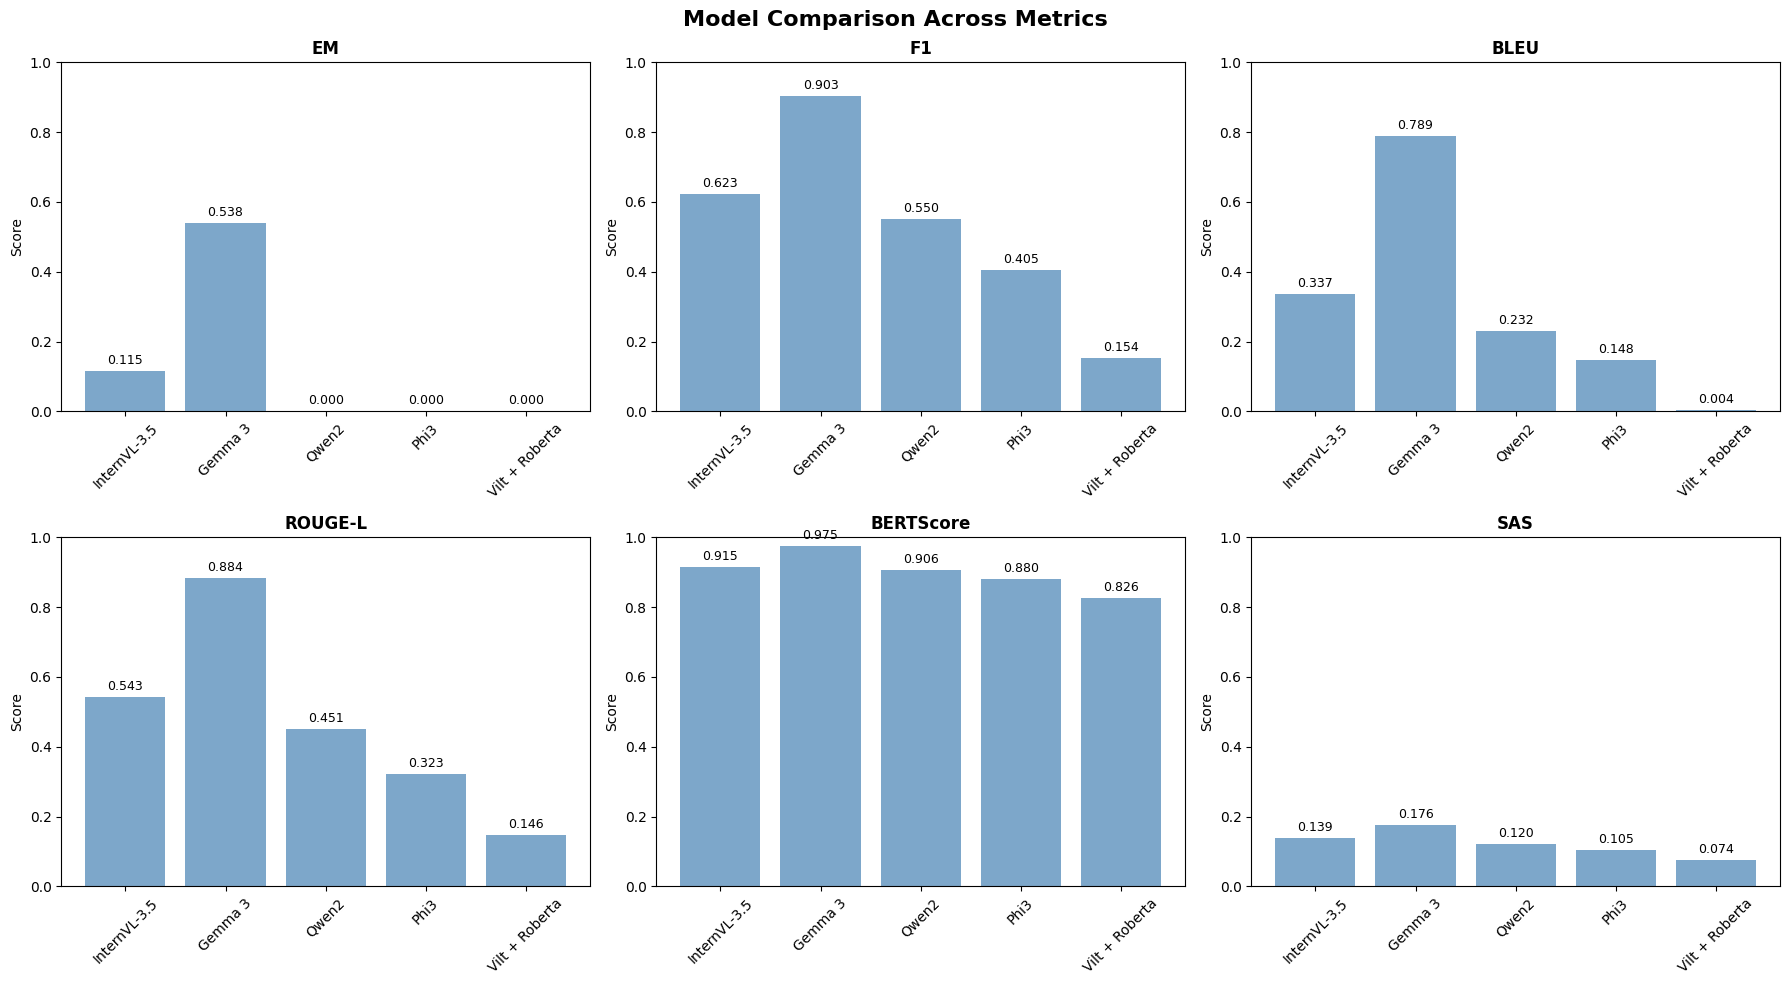


Comparison plot saved as 'model_comparison.png'


In [ ]:
import matplotlib.pyplot as plt

# Create comparison plot
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Model Comparison Across Metrics', fontsize=16, fontweight='bold')

metrics = ['EM', 'F1', 'BLEU', 'ROUGE-L', 'BERTScore', 'SAS']
axes = axes.flatten()

for idx, metric in enumerate(metrics):
    ax = axes[idx]
    metric_values = [results_df[f'{model}_{metric}'].mean() for model in model_columns]
    model_names = [m.replace(' Answers1', '') for m in model_columns]

    ax.bar(model_names, metric_values, color='steelblue', alpha=0.7)
    ax.set_ylabel('Score')
    ax.set_title(metric, fontweight='bold')
    ax.set_ylim([0, 1])
    ax.tick_params(axis='x', rotation=45)

    # Add value labels on bars
    for i, v in enumerate(metric_values):
        ax.text(i, v + 0.02, f'{v:.3f}', ha='center', fontsize=9)

plt.tight_layout()
plt.savefig('model_comparison.png', dpi=300, bbox_inches='tight')
plt.show()
print("\nComparison plot saved as 'model_comparison.png'")

# PART 6: EXPORT RESULTS

In [ ]:
# Save detailed results to Excel
output_file = 'qa_evaluation_results.xlsx'
with pd.ExcelWriter(output_file, engine='openpyxl') as writer:
    results_df.to_excel(writer, sheet_name='Detailed Results', index=False)
    summary_df.to_excel(writer, sheet_name='Summary', index=False)

print(f"\nDetailed results saved to '{output_file}'")


Detailed results saved to 'qa_evaluation_results.xlsx'


In [ ]:
# Display sample results
print("\n" + "=" * 80)
print("SAMPLE DETAILED RESULTS (First 5 rows)")
print("=" * 80)
print(results_df[['Type', 'Question', 'InternVL-3.5_EM', 'InternVL-3.5_F1', 'InternVL-3.5_BLEU', 'InternVL-3.5_ROUGE-L', 'InternVL-3.5_BERTScore', 'InternVL-3.5_SAS']].head())


SAMPLE DETAILED RESULTS (First 5 rows)
      Type                                           Question  \
0  Factoid  What are the animal found dead in Kaziranga Na...   
1  Factoid  In which place of Cachar district, landslide o...   
2  Factoid  What is the epicenter of earthquake in july 16...   
3  Factoid  Which are the states remained snapped during t...   
4  Factoid  What was the magnitude of earthquake in the ep...   

   InternVL-3.5_EM  InternVL-3.5_F1  InternVL-3.5_BLEU  InternVL-3.5_ROUGE-L  \
0              0.0         0.653846           0.196838              0.538462   
1              0.0         0.516129           0.091638              0.484848   
2              0.0         0.818182           0.419242              0.727273   
3              0.0         0.368421           0.000000              0.222222   
4              0.0         0.742857           0.288389              0.619048   

   InternVL-3.5_BERTScore  InternVL-3.5_SAS  
0                0.929107          0.13614

In [ ]:
cols = [
    'Type', 'Question',
    'InternVL-3.5_EM', 'InternVL-3.5_F1', 'InternVL-3.5_BLEU', 'InternVL-3.5_ROUGE-L', 'InternVL-3.5_BERTScore', 'InternVL-3.5_SAS',
    'Gemma 3_EM', 'Gemma 3_F1', 'Gemma 3_BLEU', 'Gemma 3_ROUGE-L', 'Gemma 3_BERTScore', 'Gemma 3_SAS',
    'Qwen2_EM', 'Qwen2_F1', 'Qwen2_BLEU', 'Qwen2_ROUGE-L', 'Qwen2_BERTScore', 'Qwen2_SAS',
    'Phi3_EM', 'Phi3_F1', 'Phi3_BLEU', 'Phi3_ROUGE-L', 'Phi3_BERTScore', 'Phi3_SAS',
    'Vilt + Roberta_EM', 'Vilt + Roberta_F1', 'Vilt + Roberta_BLEU', 'Vilt + Roberta_ROUGE-L', 'Vilt + Roberta_BERTScore', 'Vilt + Roberta_SAS',
]

print("\n" + "=" * 80)
print("ALL DETAILED RESULTS (ALL MODELS)")
print("=" * 80)
print(results_df[cols].to_string(index=False))



ALL DETAILED RESULTS (ALL MODELS)
       Type                                                                                                               Question  InternVL-3.5_EM  InternVL-3.5_F1  InternVL-3.5_BLEU  InternVL-3.5_ROUGE-L  InternVL-3.5_BERTScore  InternVL-3.5_SAS  Gemma 3_EM  Gemma 3_F1  Gemma 3_BLEU  Gemma 3_ROUGE-L  Gemma 3_BERTScore  Gemma 3_SAS  Qwen2_EM  Qwen2_F1  Qwen2_BLEU  Qwen2_ROUGE-L  Qwen2_BERTScore  Qwen2_SAS  Phi3_EM  Phi3_F1  Phi3_BLEU  Phi3_ROUGE-L  Phi3_BERTScore  Phi3_SAS  Vilt + Roberta_EM  Vilt + Roberta_F1  Vilt + Roberta_BLEU  Vilt + Roberta_ROUGE-L  Vilt + Roberta_BERTScore  Vilt + Roberta_SAS
    Factoid                                       What are the animal found dead in Kaziranga National Park during Flood in 2012 ?              0.0         0.653846           0.196838              0.538462                0.929107          0.136143         0.0    0.830189      0.419010         0.730769           0.963488     0.140870       0.0  0.434783   

# PART 7: DETAILED INTERPRETATION GUIDE

In [ ]:
print("\n" + "=" * 80)
print("METRIC INTERPRETATION GUIDE")
print("=" * 80)


METRIC INTERPRETATION GUIDE


In [ ]:
interpretation = """
1. EXACT MATCH (EM):
   - Range: 0 to 1 (0% to 100%)
   - Definition: 1 if normalized prediction equals normalized ground truth, 0 otherwise
   - Use Case: Best for factoid questions with single-word or short answers
   - Limitation: Too strict - penalizes semantically correct but differently worded answers

2. F1-SCORE (Token-Level Overlap):
   - Range: 0 to 1
   - Definition: Harmonic mean of precision and recall of token overlap
   - Formula: F1 = 2 * (Precision * Recall) / (Precision + Recall)
   - Use Case: Standard metric for SQuAD and extractive QA
   - Limitation: Misses semantic equivalence without token overlap

3. BLEU (Bilingual Evaluation Understudy):
   - Range: 0 to 1
   - Definition: N-gram precision with brevity penalty
   - Use Case: Useful for comparing different model versions (relative metric)
   - Limitation: Poor correlation with human judgment; often scores synonyms as wrong

4. ROUGE-L (Longest Common Subsequence):
   - Range: 0 to 1
   - Definition: F1 of longest common subsequence between prediction and ground truth
   - Use Case: Better than BLEU for longer answers; insensitive to word order
   - Limitation: Still lexical-based; doesn't capture semantic similarity

5. BERTSCORE (Contextual Embedding-Based):
   - Range: 0 to 1
   - Definition: Cosine similarity between contextual BERT embeddings of tokens
   - Components: Precision, Recall, and F1 calculated from token similarities
   - Use Case: Excellent for abstractive QA; captures synonyms and paraphrases
   - Strength: Correlates well with human judgment (ρ = 0.65-0.75 typically)

6. SAS (Semantic Answer Similarity):
   - Range: 0 to 1 (normalized from 0-5 internal score)
   - Definition: Cross-encoder fine-tuned on semantic similarity tasks
   - Method: Processes ground truth and prediction together for richer comparison
   - Use Case: Best metric for production systems; highest human correlation
   - Strength: Highest correlation with human judgment (ρ = 0.56-0.75)
   - Limitation: Computationally slower than BERTScore

RECOMMENDED METRIC SELECTION:
- Development Phase: Use EM + F1 + ROUGE-L for quick iteration
- Validation: Add BERTScore for semantic validation
- Production: Prioritize SAS for final performance assessment
- Publication: Report all metrics; emphasize SAS score
"""

print(interpretation)

print("\n" + "=" * 80)
print("EXECUTION COMPLETED SUCCESSFULLY!")
print("=" * 80)


1. EXACT MATCH (EM):
   - Range: 0 to 1 (0% to 100%)
   - Definition: 1 if normalized prediction equals normalized ground truth, 0 otherwise
   - Use Case: Best for factoid questions with single-word or short answers
   - Limitation: Too strict - penalizes semantically correct but differently worded answers

2. F1-SCORE (Token-Level Overlap):
   - Range: 0 to 1
   - Definition: Harmonic mean of precision and recall of token overlap
   - Formula: F1 = 2 * (Precision * Recall) / (Precision + Recall)
   - Use Case: Standard metric for SQuAD and extractive QA
   - Limitation: Misses semantic equivalence without token overlap

3. BLEU (Bilingual Evaluation Understudy):
   - Range: 0 to 1
   - Definition: N-gram precision with brevity penalty
   - Use Case: Useful for comparing different model versions (relative metric)
   - Limitation: Poor correlation with human judgment; often scores synonyms as wrong

4. ROUGE-L (Longest Common Subsequence):
   - Range: 0 to 1
   - Definition: F1 of lon